In [1]:
!pip install transformers==4.57.6 datasets==3.6.0 sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 77.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 34.4 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.4.1
    Uninstalling huggingface_hub-1.4.1:
      Successfully uninstalled huggingface_hub-1.4.1
  Attempting uninstall: transformers
    Found existing installation: transformers 5.0.0
    Uninstalling transformers-5.0.0:
      Successfully uninstalled transformers-5.0.0
  Attempting uninstall: datasets
    Found existing installation: datasets 4.0.0
    Uninstalling datasets-4.0.0:
      Successfully uninstalled datasets-4.0.0


In [2]:
from datasets import load_dataset

data = load_dataset("kde4", lang1='en', lang2='fr')
data

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

kde4.py: 0.00B [00:00, ?B/s]

The repository for kde4 contains custom code which must be executed to correctly load the dataset. You can inspect the repository content at https://hf.co/datasets/kde4.
You can avoid this prompt in future by passing the argument `trust_remote_code=True`.

Do you wish to run the custom code? [y/N] y


Generating train split:   0%|          | 0/210173 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'translation'],
        num_rows: 210173
    })
})

In [3]:
small = data['train'].shuffle(seed=42).select(range(1_000))

In [4]:
split = small.train_test_split(seed=42)

In [5]:
split['train'][0]


{'id': '169005',
 'translation': {'en': '& Reduce Tree', 'fr': "& Refermer l' arborescence"}}

In [6]:
from transformers import AutoTokenizer

In [7]:
checkpoint = 'Helsinki-NLP/opus-mt-en-fr'

In [8]:
tokenizer = AutoTokenizer.from_pretrained(checkpoint)

tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.12/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


In [9]:
en = split['train'][5]['translation']['en']
fr = split['train'][5]['translation']['fr']
en, fr

('You can either pick a file or enter its name in the Location: box.',
 'Vous pouvez soit choisir un fichier soit saisir son nom dans la zone de texte Emplacement.')

In [10]:
inputs = tokenizer(en)
inputs

{'input_ids': [213, 115, 1828, 8437, 15, 1437, 57, 3307, 96, 1129, 18, 4, 4577, 37, 5311, 3, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [11]:
targets = tokenizer(text_target=fr)
targets

{'input_ids': [344, 1069, 345, 4094, 34, 2428, 345, 9315, 113, 689, 31, 8, 1283, 5, 1470, 21708, 3, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [12]:
tokenizer.convert_ids_to_tokens(targets['input_ids'])

['▁Vous',
 '▁pouvez',
 '▁soit',
 '▁choisir',
 '▁un',
 '▁fichier',
 '▁soit',
 '▁saisir',
 '▁son',
 '▁nom',
 '▁dans',
 '▁la',
 '▁zone',
 '▁de',
 '▁texte',
 '▁Emplacement',
 '.',
 '</s>']

In [13]:
bad_targets = tokenizer(fr)
bad_targets

{'input_ids': [461, 2130, 5909, 6020, 590, 239, 567, 9071, 900, 1248, 34, 5094, 3534, 108, 239, 567, 62, 1794, 1248, 113, 170, 122, 31, 8, 1283, 5, 1863, 51, 9831, 35646, 3, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}

In [14]:
tokenizer.convert_ids_to_tokens(bad_targets['input_ids'])

['▁V',
 'ous',
 '▁po',
 'uv',
 'ez',
 '▁so',
 'it',
 '▁cho',
 'is',
 'ir',
 '▁un',
 '▁fi',
 'chi',
 'er',
 '▁so',
 'it',
 '▁s',
 'ais',
 'ir',
 '▁son',
 '▁no',
 'm',
 '▁dans',
 '▁la',
 '▁zone',
 '▁de',
 '▁text',
 'e',
 '▁Em',
 'placement',
 '.',
 '</s>']

(array([469., 131.,  40.,  28.,  10.,  15.,  15.,   5.,   5.,   4.,   0.,
          6.,   4.,   3.,   2.,   1.,   2.,   1.,   1.,   1.,   1.,   2.,
          0.,   2.,   1.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.]),
 array([1.00000e+00, 2.67200e+01, 5.24400e+01, 7.81600e+01, 1.03880e+02,
        1.29600e+02, 1.55320e+02, 1.81040e+02, 2.06760e+02, 2.32480e+02,
        2.58200e+02, 2.83920e+02, 3.09640e+02, 3.35360e+02, 3.61080e+02,
        3.86800e+02, 4.12520e+02, 4.38240e+02, 4.63960e+02, 4.89680e+02,
        5.15400e+02, 5.41120e+02, 5.66840e+02, 5.92560e+02, 6.18280e+02,
        6.44000e+02, 6.69720e+02, 6.95440e+02, 7.21160e+02, 7.46880e+02,
        7.72600e+02, 7.98320e+02, 8.24040e+02, 8.49760e+02, 8.75480e+02,
        9.01200e+02, 9.26920e+02, 9.52640e+02, 9.78360e+02, 1.00408e+03,
        1.02980e+03, 1.05552e+03, 1.08124e+03, 1.10696e+03, 1.13268e+03,
 

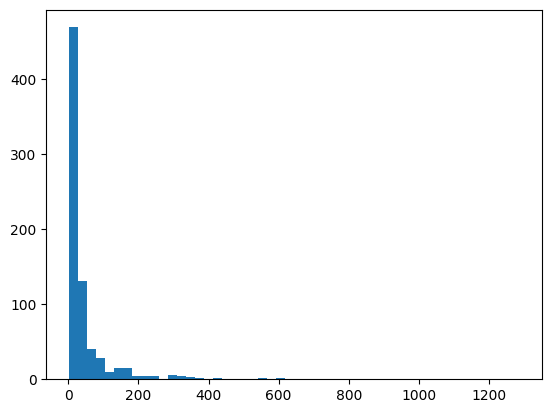

In [15]:
import matplotlib.pyplot as plt

train = split['train']['translation']
input_lens = [len(tr['en']) for tr in train]

plt.hist(input_lens, bins=50)

(array([491., 120.,  51.,  19.,  14.,  13.,   8.,   4.,   2.,   7.,   3.,
          4.,   4.,   3.,   0.,   2.,   1.,   2.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   1.]),
 array([1.00000e+00, 4.20600e+01, 8.31200e+01, 1.24180e+02, 1.65240e+02,
        2.06300e+02, 2.47360e+02, 2.88420e+02, 3.29480e+02, 3.70540e+02,
        4.11600e+02, 4.52660e+02, 4.93720e+02, 5.34780e+02, 5.75840e+02,
        6.16900e+02, 6.57960e+02, 6.99020e+02, 7.40080e+02, 7.81140e+02,
        8.22200e+02, 8.63260e+02, 9.04320e+02, 9.45380e+02, 9.86440e+02,
        1.02750e+03, 1.06856e+03, 1.10962e+03, 1.15068e+03, 1.19174e+03,
        1.23280e+03, 1.27386e+03, 1.31492e+03, 1.35598e+03, 1.39704e+03,
        1.43810e+03, 1.47916e+03, 1.52022e+03, 1.56128e+03, 1.60234e+03,
        1.64340e+03, 1.68446e+03, 1.72552e+03, 1.76658e+03, 1.80764e+03,
 

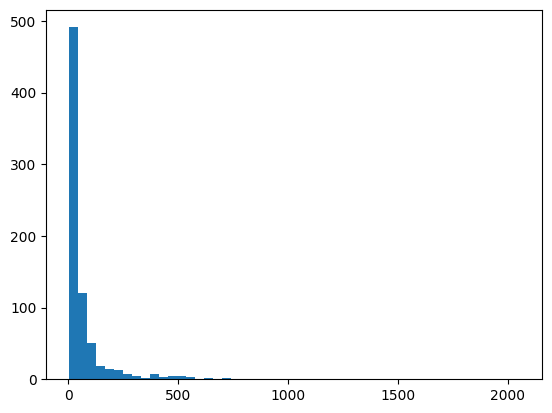

In [16]:
target_lens = [len(tr['fr']) for tr in train]

plt.hist(target_lens, bins=50)

In [17]:
max_input_len = 128
max_target_len = 128

def tokenizer_fn(batch):
  inputs = [x['en'] for x in batch['translation']]
  targets = [x['fr'] for x in batch['translation']]

  tokenized_inputs = tokenizer(inputs, max_length=max_input_len, truncation=True)
  tokenized_targets = tokenizer(text_target=inputs, max_length=max_target_len, truncation=True)

  tokenized_inputs['labels'] = tokenized_targets['input_ids']
  return tokenized_inputs

In [18]:
tokenized_datasets = split.map(tokenizer_fn,
                              batched=True,
                              remove_columns=split['train'].column_names)

Map:   0%|          | 0/750 [00:00<?, ? examples/s]

Map:   0%|          | 0/250 [00:00<?, ? examples/s]

In [19]:
from transformers import AutoModelForSeq2SeqLM

model = AutoModelForSeq2SeqLM.from_pretrained(checkpoint)

pytorch_model.bin:   0%|          | 0.00/301M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

In [20]:
from transformers import DataCollatorForSeq2Seq

data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

In [21]:
[tokenized_datasets['train'][i] for i in range(1, 3)]

[{'input_ids': [526, 3261, 0],
  'attention_mask': [1, 1, 1],
  'labels': [526, 3261, 0]},
 {'input_ids': [3492,
   3070,
   6443,
   37,
   443,
   61,
   32,
   317,
   2203,
   4824,
   514,
   1807,
   971,
   4,
   4124,
   3,
   0],
  'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
  'labels': [3492,
   14,
   1360,
   9,
   21303,
   259,
   37,
   47,
   483,
   61,
   32,
   317,
   2203,
   4824,
   514,
   357,
   352,
   5482,
   971,
   4,
   39,
   29830,
   3,
   0]}]

model.safetensors:   0%|          | 0.00/301M [00:00<?, ?B/s]

In [22]:
batch = data_collator([tokenized_datasets['train'][i] for i in range(1, 3)])

In [23]:
batch.keys()

KeysView({'input_ids': tensor([[  526,  3261,     0, 59513, 59513, 59513, 59513, 59513, 59513, 59513,
         59513, 59513, 59513, 59513, 59513, 59513, 59513],
        [ 3492,  3070,  6443,    37,   443,    61,    32,   317,  2203,  4824,
           514,  1807,   971,     4,  4124,     3,     0]]), 'attention_mask': tensor([[1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]]), 'labels': tensor([[  526,  3261,     0,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,  -100,  -100],
        [ 3492,    14,  1360,     9, 21303,   259,    37,    47,   483,    61,
            32,   317,  2203,  4824,   514,   357,   352,  5482,   971,     4,
            39, 29830,     3,     0]]), 'decoder_input_ids': tensor([[59513,   526,  3261,     0, 59513, 59513, 59513, 59513, 59513, 59513,
         59513, 59513, 59513, 59513, 59513, 59513, 59

In [24]:
batch['labels']

tensor([[  526,  3261,     0,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,  -100,
          -100,  -100,  -100,  -100],
        [ 3492,    14,  1360,     9, 21303,   259,    37,    47,   483,    61,
            32,   317,  2203,  4824,   514,   357,   352,  5482,   971,     4,
            39, 29830,     3,     0]])

In [25]:
batch['decoder_input_ids']

tensor([[59513,   526,  3261,     0, 59513, 59513, 59513, 59513, 59513, 59513,
         59513, 59513, 59513, 59513, 59513, 59513, 59513, 59513, 59513, 59513,
         59513, 59513, 59513, 59513],
        [59513,  3492,    14,  1360,     9, 21303,   259,    37,    47,   483,
            61,    32,   317,  2203,  4824,   514,   357,   352,  5482,   971,
             4,    39, 29830,     3]])

In [26]:
tokenizer.convert_ids_to_tokens(batch['decoder_input_ids'][0])

['<pad>',
 '▁K',
 'DE',
 '</s>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>',
 '<pad>']

In [27]:
#tokenizer.convert_ids_to_tokens(batch['labels'][0])

In [28]:
print(f"Special tokens: {tokenizer.special_tokens_map}")

Special tokens: {'eos_token': '</s>', 'unk_token': '<unk>', 'pad_token': '<pad>'}


In [29]:
tokenizer.convert_ids_to_tokens(0)

'</s>'

In [30]:
tokenizer.convert_tokens_to_ids('<pad>')

59513

In [31]:
split['train'][1]

{'id': '47571', 'translation': {'en': 'KDE', 'fr': 'KDE'}}

In [32]:
!pip install sacrebleu bert-score

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.1/61.1 kB 3.2 MB/s eta 0:00:00


In [33]:
!pip install evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 5.3 MB/s eta 0:00:00


In [34]:
import evaluate

bleu_metric = evaluate.load('sacrebleu')
bert_metric = evaluate.load('bertscore')

In [35]:
bleu_metric.compute(predictions=['I love cats'], references=[['I love cats']])

{'score': 0.0,
 'counts': [3, 2, 1, 0],
 'totals': [3, 2, 1, 0],
 'precisions': [100.0, 100.0, 100.0, 0.0],
 'bp': 1.0,
 'sys_len': 3,
 'ref_len': 3}

In [36]:
s = 'Marian is an efficient NMT framework written in pure C++'

bleu_metric.compute(predictions=[s], references=[[s]])

{'score': 100.00000000000004,
 'counts': [12, 11, 10, 9],
 'totals': [12, 11, 10, 9],
 'precisions': [100.0, 100.0, 100.0, 100.0],
 'bp': 1.0,
 'sys_len': 12,
 'ref_len': 12}

In [37]:
bert_metric.compute(predictions=['I love cats'], references=[['I love cats']], lang='en')

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'precision': [1.0],
 'recall': [1.0],
 'f1': [1.0],
 'hashcode': 'roberta-large_L17_no-idf_version=0.3.12(hug_trans=4.57.6)'}

In [38]:
import numpy as np

def compute_metrics(preds_and_labels):
  preds, labels = preds_and_labels

  decoded_preds = tokenizer.batch_decode(preds, skip_special_tokens=True)
  labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

  decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

  decoded_preds = [pred.strip() for pred in decoded_preds]
  decoded_labels = [label.strip() for label in decoded_labels]

  bleu = bleu_metric.compute(predictions=decoded_preds, references=decoded_labels)
  bert_score = bert_metric.compute(predictions=decoded_preds, references=decoded_labels, lang='fr')

  return { 'bleu': bleu['score'], 'bert_score': np.mean(bert_score['f1']) }

In [39]:
from transformers import Seq2SeqTrainingArguments

In [40]:
training_args = Seq2SeqTrainingArguments(
    'finetuned-model',
    # output_dir='training_dir',
    # eval_strategy='steps',
    # eval_steps=10,
    eval_strategy='no',
    save_strategy='epoch',
    learning_rate = 2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    weight_decay=0.01,
    save_total_limit=3,
    num_train_epochs=3,
    predict_with_generate=True,
    fp16=True
)

In [41]:
from transformers import Seq2SeqTrainer

In [42]:
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_datasets['train'],
    # eval_dataset=tokenized_datasets['test'].select(range(10)),
    eval_dataset=tokenized_datasets['test'],
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

In [43]:
trainer.evaluate(max_length=max_target_len)

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/714M [00:00<?, ?B/s]

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: Enter your choice:

 3


wandb: You chose "Don't visualize my results"
wandb: Using W&B in offline mode.
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


{'eval_loss': 1.148159146308899,
 'eval_model_preparation_time': 0.011,
 'eval_bleu': 11.43156719936738,
 'eval_bert_score': 0.8194882442951202,
 'eval_runtime': 41.9551,
 'eval_samples_per_second': 5.959,
 'eval_steps_per_second': 0.095}

In [44]:
trainer.train()

Step,Training Loss


/usr/local/lib/python3.12/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 512, 'num_beams': 4, 'bad_words_ids': [[59513]]}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(


TrainOutput(global_step=72, training_loss=0.44686253865559894, metrics={'train_runtime': 36.3157, 'train_samples_per_second': 61.957, 'train_steps_per_second': 1.983, 'total_flos': 51206128533504.0, 'train_loss': 0.44686253865559894, 'epoch': 3.0})

In [45]:
trainer.evaluate(max_length=max_target_len)

{'eval_loss': 0.2678326964378357,
 'eval_model_preparation_time': 0.011,
 'eval_bleu': 85.4031164392344,
 'eval_bert_score': 0.9782306349277496,
 'eval_runtime': 21.2083,
 'eval_samples_per_second': 11.788,
 'eval_steps_per_second': 0.189,
 'epoch': 3.0}

In [46]:
trainer.save_model('my_saved_model')

In [47]:
from transformers import pipeline

In [48]:
import transformers
print(transformers.__version__)

4.57.6


In [49]:
!pip index versions transformers

transformers (5.2.0)
Available versions: 5.2.0, 5.1.0, 5.0.0, 4.57.6, 4.57.5, 4.57.4, 4.57.3, 4.57.2, 4.57.1, 4.56.2, 4.56.1, 4.56.0, 4.55.4, 4.55.3, 4.55.2, 4.55.1, 4.55.0, 4.54.1, 4.54.0, 4.53.3, 4.53.2, 4.53.1, 4.53.0, 4.52.4, 4.52.3, 4.52.2, 4.52.1, 4.51.3, 4.51.2, 4.51.1, 4.51.0, 4.50.3, 4.50.2, 4.50.1, 4.50.0, 4.49.0, 4.48.3, 4.48.2, 4.48.1, 4.48.0, 4.47.1, 4.47.0, 4.46.3, 4.46.2, 4.46.1, 4.45.2, 4.45.1, 4.45.0, 4.44.2, 4.44.1, 4.44.0, 4.43.4, 4.43.3, 4.43.2, 4.43.1, 4.43.0, 4.42.4, 4.42.3, 4.42.2, 4.42.1, 4.42.0, 4.41.2, 4.41.1, 4.41.0, 4.40.2, 4.40.1, 4.40.0, 4.39.3, 4.39.2, 4.39.1, 4.39.0, 4.38.2, 4.38.1, 4.38.0, 4.37.2, 4.37.1, 4.37.0, 4.36.2, 4.36.1, 4.36.0, 4.35.2, 4.35.1, 4.35.0, 4.34.1, 4.34.0, 4.33.3, 4.33.2, 4.33.1, 4.33.0, 4.32.1, 4.32.0, 4.31.0, 4.30.2, 4.30.1, 4.30.0, 4.29.2, 4.29.1, 4.29.0, 4.28.1, 4.28.0, 4.27.4, 4.27.3, 4.27.2, 4.27.1, 4.27.0, 4.26.1, 4.26.0, 4.25.1, 4.24.0, 4.23.1, 4.23.0, 4.22.2, 4.22.1, 4.22.0, 4.21.3, 4.21.2, 4.21.1, 4.21.0, 4.20.1, 4.20.0, 4.

In [50]:
translation = pipeline(task='translation', model='my_saved_model', device=0)

# translation = pipeline('translation_en_to_fr', model='my_saved_model', device=0)

/usr/local/lib/python3.12/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cuda:0


In [51]:
translation('I hope this course has helped you on your data science journey!')

[{'translation_text': "J'espère que ce cours vous a aidé sur votre data science voyage!"}]